<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 1 · Sesión 2: Calidad de cartera, pérdidas, provisiones y rentabilidad</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: indicadores de mora, castigos, provisiones SBS, cosechas, roll rates y P&L por producto</div>
</div>

## Objetivos de la sesión (2 horas)

1. Construir desde datos crédito-mes los **indicadores de calidad de cartera** que reporta un banco peruano: cartera atrasada, mora por tramos, cartera pesada, castigos y coberturas.
2. Entender por qué la **mora contable engaña**: efecto denominador (crecimiento) y efecto castigos.
3. Calcular **provisiones** con las categorías de la Res. SBS N.° 11356-2008 y el **costo de riesgo**.
4. Leer **cosechas** (*vintages*) y **roll rates** como indicadores adelantados.
5. Armar un **P&L simplificado por producto**: margen, pérdidas y contribución.

**Datos:** `cartera_panel_mensual.csv.gz`: panel **sintético** de 16 mil créditos minoristas (tarjeta, consumo, microempresa, vehicular, hipotecario), originados entre enero de 2022 y diciembre de 2025, y observados mes a mes hasta septiembre de 2026. Incluye atraso, castigos y recuperaciones. El riesgo responde a un índice macro ilustrativo (`macro_peru_ilustrativa.csv`).

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 15 min | Estructura del panel crédito-mes |
| 2 | 30 min | Indicadores de calidad de cartera y sus trampas |
| 3 | 25 min | Provisiones SBS, cobertura y costo de riesgo |
| 4 | 25 min | Cosechas y roll rates |
| 5 | 15 min | Rentabilidad por producto |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

## 1. El panel crédito-mes

In [2]:
p = pd.read_csv(DATA / "cartera_panel_mensual.csv.gz")
macro = pd.read_csv(DATA / "macro_peru_ilustrativa.csv")
sbs = pd.read_csv(DATA / "sbs_categorias_provisiones_consumo.csv")
print(p.shape); display(p.head(8)); display(sbs)

(286560, 17)


,id_credito,producto,segmento_riesgo,region,canal,cosecha,monto_desembolsado,plazo_meses,tasa_anual,periodo,mob,saldo,dias_atraso,estado,monto_castigo,recupero,bucket_atraso
0,CR100000,Tarjeta de crédito,C,Lima Metropolitana,Agencia,2023-09,"12,107.0900",36,0.5850,2023-10,1,"11,977.3400",0,Vigente,0.0000,0.0000,0
1,CR100000,Tarjeta de crédito,C,Lima Metropolitana,Agencia,2023-09,"12,107.0900",36,0.5850,2023-11,2,"11,841.2600",0,Vigente,0.0000,0.0000,0
2,CR100000,Tarjeta de crédito,C,Lima Metropolitana,Agencia,2023-09,"12,107.0900",36,0.5850,2023-12,3,"11,698.5400",0,Vigente,0.0000,0.0000,0
3,CR100000,Tarjeta de crédito,C,Lima Metropolitana,Agencia,2023-09,"12,107.0900",36,0.5850,2024-01,4,"11,548.8700",0,Vigente,0.0000,0.0000,0
4,CR100000,Tarjeta de crédito,C,Lima Metropolitana,Agencia,2023-09,"12,107.0900",36,0.5850,2024-02,5,"11,391.9000",0,Vigente,0.0000,0.0000,0
5,CR100000,Tarjeta de crédito,C,Lima Metropolitana,Agencia,2023-09,"12,107.0900",36,0.5850,2024-03,6,"11,227.2800",0,Vigente,0.0000,0.0000,0
6,CR100000,Tarjeta de crédito,C,Lima Metropolitana,Agencia,2023-09,"12,107.0900",36,0.5850,2024-04,7,"11,054.6300",0,Vigente,0.0000,0.0000,0
7,CR100000,Tarjeta de crédito,C,Lima Metropolitana,Agencia,2023-09,"12,107.0900",36,0.5850,2024-05,8,"10,873.5700",0,Vigente,0.0000,0.0000,0


,categoria,dias_atraso_consumo_min,dias_atraso_consumo_max,provision_sin_garantia_pct
0,0 - Normal,0,8,1.0000
1,1 - Con Problemas Potenciales (CPP),9,30,5.0000
2,2 - Deficiente,31,60,25.0000
3,3 - Dudoso,61,120,60.0000
4,4 - Pérdida,121,99999,100.0000


In [3]:
# Un crédito a lo largo de su vida
ejemplo = p[p.id_credito == p.loc[p.monto_castigo > 0, "id_credito"].iloc[3]]
ejemplo[["id_credito", "producto", "cosecha", "periodo", "mob", "saldo", "dias_atraso", "bucket_atraso", "estado", "monto_castigo", "recupero"]]

,id_credito,producto,cosecha,periodo,mob,saldo,dias_atraso,bucket_atraso,estado,monto_castigo,recupero
1607,CR100093,Consumo no revolvente,2023-09,2023-10,1,"35,287.4700",17,1-30,Vigente,0.0000,0.0000
1608,CR100093,Consumo no revolvente,2023-09,2023-11,2,"35,287.4700",25,1-30,Vigente,0.0000,0.0000
1609,CR100093,Consumo no revolvente,2023-09,2023-12,3,"35,287.4700",34,31-60,Vigente,0.0000,0.0000
1610,CR100093,Consumo no revolvente,2023-09,2024-01,4,"35,287.4700",69,61-90,Vigente,0.0000,0.0000
1611,CR100093,Consumo no revolvente,2023-09,2024-02,5,"35,287.4700",110,91-120,Vigente,0.0000,0.0000
1612,CR100093,Consumo no revolvente,2023-09,2024-03,6,"35,287.4700",164,121-180,Vigente,0.0000,0.0000
1613,CR100093,Consumo no revolvente,2023-09,2024-04,7,"35,287.4700",181,181+,Castigado,"35,287.4700",0.0000
1614,CR100093,Consumo no revolvente,2023-09,2024-05,8,0.0000,181,181+,Castigado,0.0000,"1,217.4900"
1615,CR100093,Consumo no revolvente,2023-09,2024-06,9,0.0000,181,181+,Castigado,0.0000,913.1200
1616,CR100093,Consumo no revolvente,2023-09,2024-07,10,0.0000,181,181+,Castigado,0.0000,684.8400


## 2. Indicadores de calidad de cartera

Definiciones simplificadas (alineadas con la terminología SBS):

| Indicador | Fórmula |
|---|---|
| Colocaciones | Saldo de créditos vigentes en balance |
| **Cartera atrasada / Mora** | Saldo con más de 30 días de atraso ÷ colocaciones (*simplificación del criterio contable SBS de crédito vencido*) |
| Mora 60+ / 90+ | Saldo con más de 60 / 90 días ÷ colocaciones |
| **Cartera pesada** | Saldo en Deficiente + Dudoso + Pérdida ÷ colocaciones |
| **Castigos** | Saldo retirado del balance (en este panel, al día 181) |
| Mora ajustada por castigos | (Atrasada + castigos 12 m) ÷ (colocaciones + castigos 12 m) |
| Mora rezagada | Atrasada_t ÷ colocaciones_{t−12} |

In [4]:
vig = p[p.estado == "Vigente"].copy()
vig["cat_sbs"] = pd.cut(vig.dias_atraso, [-1, 8, 30, 60, 120, 10_000], labels=sbs.categoria.tolist())
tasa_prov = dict(zip(sbs.categoria, sbs.provision_sin_garantia_pct / 100))
vig["provision"] = vig.saldo * vig.cat_sbs.map(tasa_prov).astype(float)

def indicadores(df_vig, df_all):
    g = df_vig.groupby("periodo")
    ind = pd.DataFrame({
        "colocaciones": g.saldo.sum(),
        "atrasada": g.apply(lambda d: d.loc[d.dias_atraso > 30, "saldo"].sum()),
        "mora60": g.apply(lambda d: d.loc[d.dias_atraso > 60, "saldo"].sum()),
        "mora90": g.apply(lambda d: d.loc[d.dias_atraso > 90, "saldo"].sum()),
        "pesada": g.apply(lambda d: d.loc[d.dias_atraso > 30, "saldo"].sum()),  # Deficiente+ en consumo = >30 días
        "provisiones": g.provision.sum(),
    })
    ga = df_all.groupby("periodo")
    ind["castigos"] = ga.monto_castigo.sum().reindex(ind.index).fillna(0)
    ind["recuperos"] = ga.recupero.sum().reindex(ind.index).fillna(0)
    ind["castigos_12m"] = ind.castigos.rolling(12, min_periods=1).sum()
    ind["ratio_mora"] = ind.atrasada / ind.colocaciones
    ind["ratio_mora60"] = ind.mora60 / ind.colocaciones
    ind["ratio_mora90"] = ind.mora90 / ind.colocaciones
    ind["mora_ajustada"] = (ind.atrasada + ind.castigos_12m) / (ind.colocaciones + ind.castigos_12m)
    ind["mora_rezagada"] = ind.atrasada / ind.colocaciones.shift(12)
    ind["cobertura"] = ind.provisiones / ind.atrasada
    # costo de riesgo anualizado: (gasto de provisiones = Δprov + castigos - recuperos) / colocaciones promedio
    ind["gasto_prov"] = ind.provisiones.diff() + ind.castigos - ind.recuperos
    ind["costo_riesgo"] = ind.gasto_prov.rolling(12).sum() / ind.colocaciones.rolling(12).mean()
    return ind

# Foco: cartera de CONSUMO (tarjeta + consumo no revolvente), donde aplican los tramos de atraso usados
cons = ["Tarjeta de crédito", "Consumo no revolvente"]
ind = indicadores(vig[vig.producto.isin(cons)], p[p.producto.isin(cons)])
ind = ind.loc["2022-07":]
ind.loc[:"2023-06", "mora_rezagada"] = np.nan        # requiere 12 meses de cartera madura para ser interpretable
ind[["colocaciones", "ratio_mora", "ratio_mora90", "mora_ajustada", "mora_rezagada", "cobertura", "costo_riesgo"]].iloc[::3]

,colocaciones,ratio_mora,ratio_mora90,mora_ajustada,mora_rezagada,cobertura,costo_riesgo
periodo,,,,,,,
2022-07,"10,487,683.2600",0.0085,0.0018,0.0085,NaN,1.7826,NaN
2022-10,"15,028,788.5400",0.0454,0.0133,0.0481,NaN,0.7165,NaN
2023-01,"19,386,900.5200",0.0557,0.0203,0.0737,NaN,0.7115,NaN
2023-04,"22,500,574.9600",0.0672,0.0228,0.1052,NaN,0.7214,0.1230
2023-07,"25,261,461.3000",0.0761,0.0357,0.1341,0.1834,0.7419,0.1421
2023-10,"27,573,934.6100",0.0735,0.0255,0.1629,0.1349,0.6921,0.1534
2024-01,"29,720,309.0600",0.0673,0.0353,0.1690,0.1032,0.8034,0.1536
2024-04,"31,662,669.6900",0.0399,0.0208,0.1566,0.0562,0.8659,0.1310
2024-07,"33,307,060.4700",0.0247,0.0099,0.1392,0.0325,0.9946,0.0990


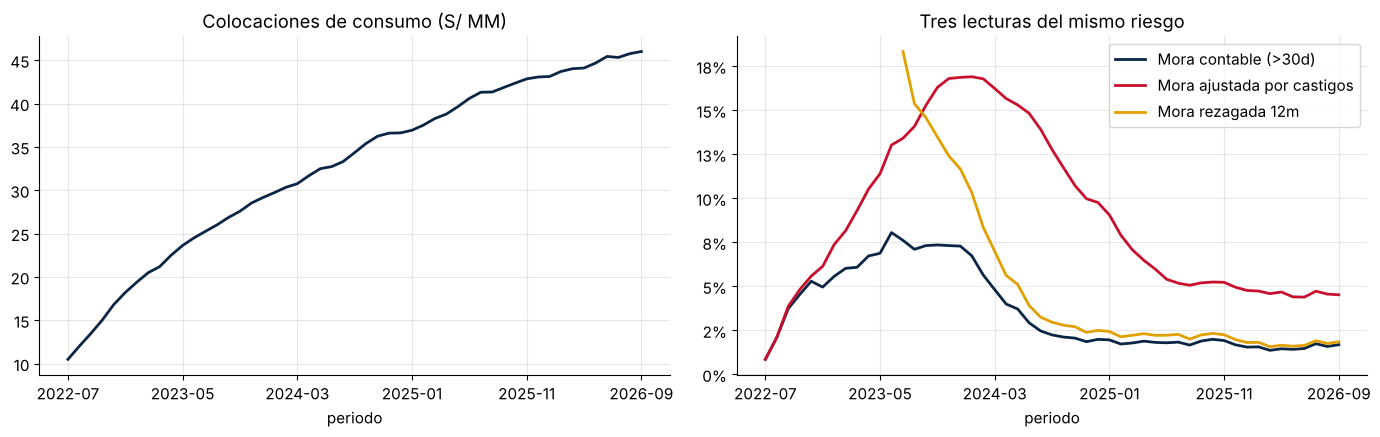

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(ind.colocaciones / 1e6).plot(ax=ax[0], color=AZUL, lw=2); ax[0].set_title("Colocaciones de consumo (S/ MM)")
for col, c, lab in [("ratio_mora", AZUL, "Mora contable (>30d)"), ("mora_ajustada", ROJO, "Mora ajustada por castigos"),
                    ("mora_rezagada", ORO, "Mora rezagada 12m")]:
    ind[col].plot(ax=ax[1], color=c, lw=2, label=lab)
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax[1].legend(); ax[1].set_title("Tres lecturas del mismo riesgo")
plt.tight_layout(); plt.show()

**Lectura obligatoria para el comité:**
- La **mora contable** puede bajar porque (a) la cartera **crece** y el denominador se infla con créditos nuevos que aún no maduran, o (b) se **castiga** cartera que deja de estar en balance.
- La **mora ajustada por castigos** devuelve al numerador lo que salió por castigo: es casi siempre bastante más alta.
- La **mora rezagada** compara la mora de hoy con la cartera de hace 12 meses y corrige el efecto crecimiento.

> Pregunta: si tu mora contable se mantiene en 4 %, pero la ajustada pasa de 8 % a 11 %, ¿qué está pasando y qué le dirías al gerente comercial?

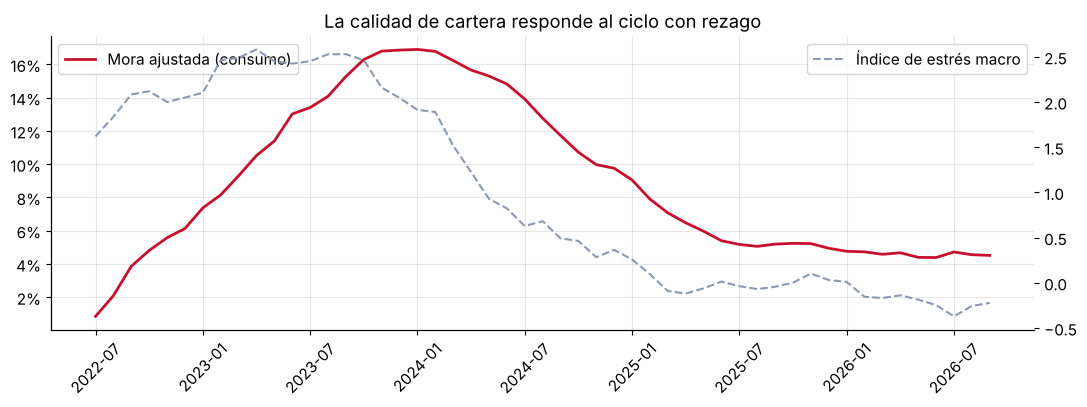

In [6]:
# Riesgo vs. ciclo macro
m = macro.set_index("periodo").loc[ind.index]
fig, ax1 = plt.subplots(figsize=(11, 4.2))
ax1.plot(ind.index, ind.mora_ajustada, color=ROJO, lw=2, label="Mora ajustada (consumo)")
ax2 = ax1.twinx(); ax2.plot(ind.index, m.indice_estres_simulado, color=GRIS, ls="--", label="Índice de estrés macro"); ax2.grid(False)
ax1.set_xticks(ind.index[::6]); ax1.tick_params(axis="x", rotation=45)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax1.legend(loc="upper left"); ax2.legend(loc="upper right")
ax1.set_title("La calidad de cartera responde al ciclo con rezago"); plt.tight_layout(); plt.show()

## 3. Provisiones SBS, cobertura y costo de riesgo

En la **Res. SBS N.° 11356-2008**, el deudor minorista se clasifica según sus días de atraso y cada categoría tiene una tasa mínima de provisión (créditos sin garantía). La provisión de la categoría *Normal* es **genérica** y puede incluir un componente procíclico; las demás son **específicas**.

> Nota: las tablas cargadas son una referencia didáctica para consumo sin garantías. En la práctica las tasas dependen del tipo de crédito, las garantías y las modificaciones normativas vigentes. **Valida siempre contra la norma actualizada.**

In [7]:
ult = vig[(vig.periodo == "2026-06") & vig.producto.isin(cons)]
dist = ult.groupby("cat_sbs", observed=True).agg(saldo=("saldo", "sum"), provision=("provision", "sum"))
dist["pct_saldo"] = dist.saldo / dist.saldo.sum()
dist["tasa_efectiva"] = dist.provision / dist.saldo
display(dist.style.format({"saldo": "{:,.0f}", "provision": "{:,.0f}", "pct_saldo": "{:.1%}", "tasa_efectiva": "{:.1%}"}))
print(f"Provisión total / colocaciones: {dist.provision.sum() / dist.saldo.sum():.2%}")
print(f"Cobertura de cartera atrasada: {ind.loc['2026-06', 'cobertura']:.0%}")

,saldo,provision,pct_saldo,tasa_efectiva
cat_sbs,,,,
0 - Normal,"44,179,517","441,795",97.3%,1.0%
1 - Con Problemas Potenciales (CPP),"581,146","29,057",1.3%,5.0%
2 - Deficiente,"248,523","62,131",0.5%,25.0%
3 - Dudoso,"326,389","195,833",0.7%,60.0%
4 - Pérdida,"92,417","92,417",0.2%,100.0%


Provisión total / colocaciones: 1.81%
Cobertura de cartera atrasada: 123%


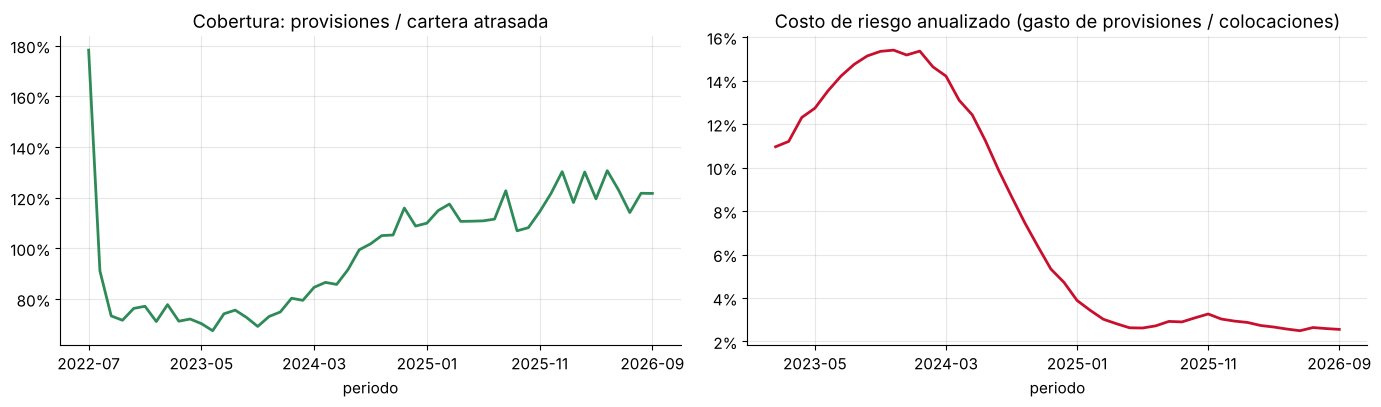

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ind.cobertura.plot(ax=ax[0], color=VERDE, lw=2); ax[0].set_title("Cobertura: provisiones / cartera atrasada")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ind.costo_riesgo.plot(ax=ax[1], color=ROJO, lw=2); ax[1].set_title("Costo de riesgo anualizado (gasto de provisiones / colocaciones)")
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout(); plt.show()

**Puente hacia IFRS 9 (Módulo 7):** la provisión SBS es *incurrida/regulatoria* por categoría. IFRS 9 exige **pérdida crediticia esperada** con información prospectiva:
$$ECL = \sum_t PD_t \times LGD_t \times EAD_t \times DF_t$$
con *staging* (12 meses vs. vida del crédito). Hoy medimos lo que **ya pasó**; en el Módulo 7 mediremos lo que **esperamos que pase**.

## 4. Cosechas (*vintage analysis*)
Una cosecha agrupa los créditos desembolsados en el mismo período y sigue su desempeño por **meses en libros (MOB)**. Permite comparar originaciones **a igual madurez**, sin el efecto denominador.

Indicador: % del monto desembolsado de la cosecha que llegó alguna vez a **60+ días o castigo** hasta el MOB *k* (*ever 60+*).

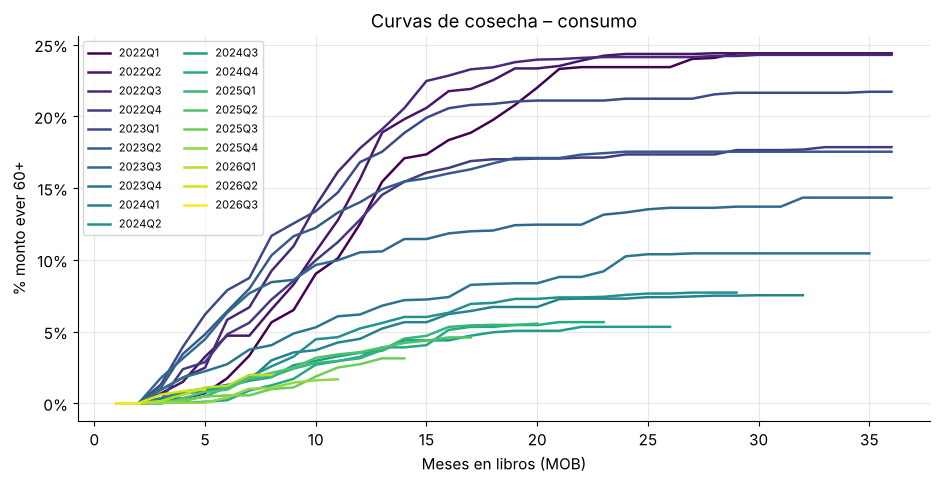

In [9]:
pc = p[p.producto.isin(cons)].copy()
pc["cosecha_q"] = pd.PeriodIndex(pc.cosecha, freq="M").asfreq("Q").astype(str)
pc["malo"] = (pc.dias_atraso > 60) | (pc.monto_castigo > 0)
primer_malo = pc[pc.malo].groupby("id_credito").mob.min()
creditos = pc.drop_duplicates("id_credito").set_index("id_credito")[["cosecha_q", "monto_desembolsado"]]
creditos["mob_malo"] = primer_malo
max_mob_cosecha = pc.groupby("cosecha_q").mob.max()

curvas = {}
for q, d in creditos.groupby("cosecha_q"):
    mobs = range(1, min(max_mob_cosecha[q], 36) + 1)
    curvas[q] = pd.Series([d.loc[d.mob_malo <= k, "monto_desembolsado"].sum() / d.monto_desembolsado.sum() for k in mobs], index=list(mobs))
vint = pd.DataFrame(curvas)

fig, ax = plt.subplots(figsize=(11, 5))
cmap = plt.cm.viridis(np.linspace(0, 1, vint.shape[1]))
for c, col in zip(vint.columns, cmap):
    ax.plot(vint.index, vint[c], color=col, lw=1.8, label=c)
ax.set_xlabel("Meses en libros (MOB)"); ax.set_ylabel("% monto ever 60+"); ax.set_title("Curvas de cosecha – consumo")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax.legend(ncol=2, fontsize=8); plt.show()

In [10]:
# Tabla tipo "triángulo" a MOB 3, 6, 12, 18
vint.loc[[3, 6, 12, 18]].T.style.format("{:.2%}", na_rep="—").background_gradient(cmap="RdYlGn_r", axis=None)

,3,6,12,18
2022Q1,0.32%,1.74%,12.51%,19.74%
2022Q2,0.68%,4.71%,15.63%,22.51%
2022Q3,0.93%,5.82%,17.78%,23.41%
2022Q4,0.21%,4.80%,12.80%,17.00%
2023Q1,1.30%,7.88%,16.81%,20.86%
2023Q2,1.06%,6.41%,14.01%,16.72%
2023Q3,1.75%,6.31%,10.52%,12.04%
2023Q4,0.94%,2.72%,6.19%,8.32%
2024Q1,0.35%,1.28%,4.49%,6.71%
2024Q2,0.14%,1.02%,5.21%,7.00%


**Lectura:** las cosechas de 2022-T4 y 2023 (originadas en un entorno de inflación y tasas altas) se deterioran **más rápido y más alto**. Las de 2024-2025 tienen mejores curvas a igual MOB. Ésta es la señal adelantada que la mora contable no da.

## 5. Roll rates: la dinámica de la morosidad
La matriz de transición muestra la probabilidad de que un crédito pase de un tramo de atraso a otro en un mes.

In [11]:
orden = ["0", "1-30", "31-60", "61-90", "91-120", "121-180", "181+"]
pr = p[p.producto.isin(cons) & (p.estado != "Cancelado")].sort_values(["id_credito", "mob"])
pr = pr[~((pr.estado == "Castigado") & (pr.monto_castigo == 0))]          # quitamos filas post-castigo (recuperos)
pr["bucket_sig"] = pr.groupby("id_credito").bucket_atraso.shift(-1)
ventana = pr[(pr.periodo >= "2025-07") & (pr.periodo <= "2026-06") & pr.bucket_sig.notna() & (pr.bucket_atraso != "181+")]
rr = pd.crosstab(ventana.bucket_atraso, ventana.bucket_sig, normalize="index").reindex(index=orden[:-1], columns=orden).fillna(0)
rr.style.format("{:.1%}").background_gradient(cmap="Blues", axis=1)

bucket_sig,0,1-30,31-60,61-90,91-120,121-180,181+
bucket_atraso,,,,,,,
0,98.5%,1.5%,0.0%,0.0%,0.0%,0.0%,0.0%
1-30,53.9%,22.8%,23.3%,0.0%,0.0%,0.0%,0.0%
31-60,17.8%,0.0%,25.8%,56.4%,0.0%,0.0%,0.0%
61-90,12.0%,0.0%,0.0%,10.6%,77.4%,0.0%,0.0%
91-120,7.5%,0.0%,0.0%,0.0%,4.0%,88.4%,0.0%
121-180,2.8%,0.0%,0.0%,0.0%,0.0%,14.4%,82.8%


In [12]:
# Roll rate "hacia adelante" (forward roll) y tasa de cura
fwd = {orden[i]: rr.loc[orden[i], orden[i + 1]] for i in range(len(orden) - 1)}
cura = rr["0"]
res = pd.DataFrame({"roll_forward": fwd, "cura_a_0": cura})
res["prob_acum_castigo"] = res.roll_forward[::-1].cumprod()[::-1]
res.style.format("{:.1%}")

,roll_forward,cura_a_0,prob_acum_castigo
0,1.5%,98.5%,0.1%
1-30,23.3%,53.9%,7.5%
31-60,56.4%,17.8%,31.9%
61-90,77.4%,12.0%,56.7%
91-120,88.4%,7.5%,73.2%
121-180,82.8%,2.8%,82.8%


`prob_acum_castigo` en el tramo `0` aproxima la probabilidad de que un crédito al día llegue a castigo **si las tasas se mantienen** (es una cadena de Markov). Es el puente intuitivo hacia las matrices de transición y la PD de vida del Módulo 7.

## 6. Rentabilidad por producto: el P&L de riesgo
Supuestos: costo de fondeo 5.5 % anual sobre saldo, costo operativo anual por producto (tarjeta 9 %, consumo 5 %, micro 8 %, vehicular 2.5 %, hipotecario 1.2 %). Los intereses se devengan sólo sobre créditos con 90 días de atraso o menos.

In [13]:
opex = {"Tarjeta de crédito": .09, "Consumo no revolvente": .05, "Microempresa": .08, "Vehicular": .025, "Hipotecario": .012}
v12 = vig[(vig.periodo > "2025-06") & (vig.periodo <= "2026-06")].copy()
v12["ingreso_int"] = np.where(v12.dias_atraso <= 90, v12.saldo * v12.tasa_anual / 12, 0)
v12["costo_fondeo"] = v12.saldo * 0.055 / 12
v12["costo_op"] = v12.saldo * v12.producto.map(opex) / 12
a12 = p[(p.periodo > "2025-06") & (p.periodo <= "2026-06")]

pl = v12.groupby("producto").agg(saldo_prom=("saldo", lambda s: s.sum() / 12), ingreso_int=("ingreso_int", "sum"),
                                 costo_fondeo=("costo_fondeo", "sum"), costo_op=("costo_op", "sum"))
pl["perdida_neta"] = a12.groupby("producto").monto_castigo.sum() - a12.groupby("producto").recupero.sum()
pl["contribucion"] = pl.ingreso_int - pl.costo_fondeo - pl.costo_op - pl.perdida_neta
for c in ["ingreso_int", "costo_fondeo", "costo_op", "perdida_neta", "contribucion"]:
    pl[c + "_%"] = pl[c] / pl.saldo_prom
pl[["saldo_prom", "ingreso_int_%", "costo_fondeo_%", "costo_op_%", "perdida_neta_%", "contribucion_%"]].style.format(
    {"saldo_prom": "{:,.0f}", **{c: "{:.1%}" for c in pl.columns if c.endswith("_%")}})

,saldo_prom,ingreso_int_%,costo_fondeo_%,costo_op_%,perdida_neta_%,contribucion_%
producto,,,,,,
Consumo no revolvente,"28,257,022",32.7%,5.5%,5.0%,1.6%,20.6%
Hipotecario,"186,712,197",7.8%,5.5%,1.2%,0.1%,1.0%
Microempresa,"13,430,130",36.0%,5.5%,8.0%,2.3%,20.2%
Tarjeta de crédito,"14,888,366",55.7%,5.5%,9.0%,4.0%,37.2%
Vehicular,"31,225,169",12.1%,5.5%,2.5%,0.1%,3.9%


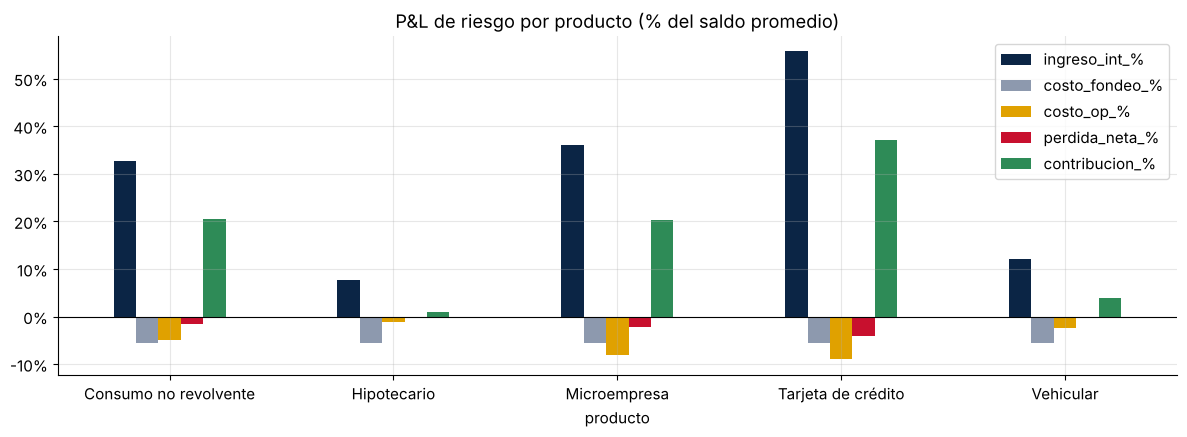

In [14]:
w = pl[["ingreso_int_%", "costo_fondeo_%", "costo_op_%", "perdida_neta_%", "contribucion_%"]].copy()
w[["costo_fondeo_%", "costo_op_%", "perdida_neta_%"]] *= -1
ax = w.plot(kind="bar", figsize=(12, 4.5), color=[AZUL, GRIS, ORO, ROJO, VERDE])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax.set_title("P&L de riesgo por producto (% del saldo promedio)")
ax.axhline(0, color="black", lw=.8); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Mensaje clave:** el producto con **mayor mora** (tarjeta, micro) puede ser también el de **mayor contribución**, porque la tasa lo compensa. La pregunta correcta no es "¿cuánta mora tengo?", sino "¿mi precio paga la pérdida, el costo y el capital?" (Módulo 8, RAROC).

## 7. Ejercicios
1. Recalcula los indicadores para **Microempresa**. ¿La mora ajustada se comporta igual que en consumo?
2. Construye la curva de cosechas con el indicador **ever 30+ a MOB 6** (*30@6*), muy usado en originación.
3. Estima el impacto en provisiones de que 10 % del saldo *Normal* migre a *CPP*.
4. ¿Qué nivel de pérdida neta haría que la tarjeta tenga contribución cero? (punto de equilibrio).